# Value Functions: Monte Carlo vs Temporal Difference Learning

**Goal:** estimate the state-value function of a fixed policy

$$V(s) = \mathbb{E}\left[G_t \mid S_t = s\right], \qquad G_t = r_{t+1} + \gamma r_{t+2} + \gamma^2 r_{t+3} + \dots$$

Every method in this notebook uses the same update and differs only in the **target**:

$$V(s) \leftarrow V(s) + \alpha\,\big(\text{target} - V(s)\big)$$

| Method | Target | When can it update? |
|---|---|---|
| Monte Carlo | $G_t$ (the real return) | only after the episode ends |
| TD(0) | $r_{t+1} + \gamma V(s_{t+1})$ | after every step (bootstraps) |
| n-step TD | $r_{t+1} + \dots + \gamma^{n-1} r_{t+n} + \gamma^n V(s_{t+n})$ | after n steps |

n-step TD contains both: **n = 1 is TD(0)** and **n = ∞ is Monte Carlo**.

## Environment: the 5-state Random Walk (Sutton & Barto)

```
[T] - A - B - C - D - E - [T]
r=0                       r=+1
```

Start in **C**. Each step goes left or right with probability 0.5. Only reaching the right end pays +1.
With $\gamma = 1$, $V(s)$ is the probability of finishing on the right, so the true values are
$V(A..E) = \tfrac16, \tfrac26, \tfrac36, \tfrac46, \tfrac56$. Knowing the exact answer lets us measure the error precisely.

!pip install torch torchvision matplotlib

In [8]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

N = 7                      # states 0..6; 0 and 6 are terminal, 1..5 are A..E
START, GAMMA = 3, 1.0
TRUE_V = torch.arange(1, 6, dtype=torch.float32) / 6.0
NAMES = "ABCDE"
INF = 10_000               # stands in for n = infinity in n-step TD

### Simulating many runs in parallel

A single run is noisy, so we average over many independent runs. Instead of a Python loop over runs,
we simulate **all runs at once**: the value table `V` has shape `(runs, states)` and one tensor operation
updates every run. Episodes end at different times, so a `valid` mask marks which runs are still going.

In [9]:
def simulate(runs, gen):
    '''
    Play one episode in each of `runs` parallel runs.
      S     (L+1, runs)  states,  S[t] = s_t
      R     (L+1, runs)  rewards, R[t] = r_t   (R[0] unused)
      valid (L,   runs)  True while the run is still inside its episode
    A finished run stays in its terminal state with reward 0 (padding).
    '''
    s = torch.full((runs,), START)
    S, R, valid = [s], [torch.zeros(runs)], []
    alive = torch.ones(runs, dtype=torch.bool)
    while alive.any():
        step = torch.where(torch.rand(runs, generator=gen) < 0.5, 1, -1)
        s = torch.where(alive, s + step, s)
        valid.append(alive)
        R.append(((s == N - 1) & alive).float())
        S.append(s)
        alive = alive & (s != 0) & (s != N - 1)
    return torch.stack(S), torch.stack(R), torch.stack(valid)


def init_table(runs):
    V = torch.full((runs, N), 0.5)
    V[:, 0] = V[:, -1] = 0.0          # terminal states are worth 0 by definition
    return V


def rms(V):
    '''RMS error vs the true values, per run, averaged over runs.'''
    return torch.sqrt(((V[:, 1:6] - TRUE_V) ** 2).mean(1)).mean().item()


# quick look at one episode
S, R, valid = simulate(1, torch.Generator().manual_seed(1))
print("states :", "".join("T" if x in (0, 6) else NAMES[x - 1] for x in S[:, 0].tolist()))
print("rewards:", R[1:, 0].tolist())

states : CBCDCDCDCBCBAT
rewards: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


## Tabular methods

`idx = torch.arange(runs)` together with `V[idx, s]` selects "row *i*, column $s_i$" for every run *i* at once.
Multiplying the update by `valid[t]` freezes runs whose episode has already ended.

### Monte Carlo
First play the **whole** episode, then compute returns backwards ($G_t = r_{t+1} + \gamma G_{t+1}$),
then move each visited state toward its real return.

In [10]:
def mc_update(V, S, R, valid, alpha):
    idx, L = torch.arange(V.shape[0]), valid.shape[0]
    G = torch.zeros_like(R)
    for t in reversed(range(L)):                  # 1) returns, computed backwards
        G[t] = R[t + 1] + GAMMA * G[t + 1]
    for t in range(L):                            # 2) move V(s_t) toward G_t
        s = S[t]
        V[idx, s] += alpha * valid[t] * (G[t] - V[idx, s])

### TD(0)
Update **after every step**, using our own current estimate $V(s')$ in place of the rest of the return.
The difference $\delta_t = r_{t+1} + \gamma V(s_{t+1}) - V(s_t)$ is the **TD error**.

In [11]:
def td0_update(V, S, R, valid, alpha):
    idx = torch.arange(V.shape[0])
    for t in range(valid.shape[0]):
        s, s_next = S[t], S[t + 1]
        td_error = R[t + 1] + GAMMA * V[idx, s_next] - V[idx, s]
        V[idx, s] += alpha * valid[t] * td_error

### n-step TD
Use *n* real rewards, then bootstrap. If the episode ends before step $t+n$, the padded rewards are 0 and
$s_{t+n}$ is terminal with $V = 0$, so the padding handles the edge case automatically.

In [12]:
def nstep_update(V, S, R, valid, alpha, n):
    idx, L = torch.arange(V.shape[0]), valid.shape[0]
    for t in range(L):
        end = min(t + n, L)
        disc = GAMMA ** torch.arange(end - t, dtype=torch.float32)
        target = (disc[:, None] * R[t + 1:end + 1]).sum(0) \
                 + GAMMA ** (end - t) * V[idx, S[end]]
        s = S[t]
        V[idx, s] += alpha * valid[t] * (target - V[idx, s])


def learning_curve(update_fn, alpha, episodes=100, runs=100, seed=0, **kw):
    '''RMS error after each episode, averaged over `runs` parallel runs.'''
    gen = torch.Generator().manual_seed(seed)
    V = init_table(runs)
    curve = [rms(V)]
    for _ in range(episodes):
        update_fn(V, *simulate(runs, gen), alpha, **kw)
        curve.append(rms(V))
    return torch.tensor(curve)

### Sanity check
With the same random episodes, n-step TD should reproduce TD(0) exactly when n = 1 and Monte Carlo exactly when n = ∞.

In [13]:
for n, fn in [(1, td0_update), (INF, mc_update)]:
    a = learning_curve(nstep_update, 0.1, episodes=20, runs=10, n=n)
    b = learning_curve(fn, 0.1, episodes=20, runs=10)
    assert torch.allclose(a, b), f"n={n} mismatch"
print("n-step TD: n=1 == TD(0), n=inf == Monte Carlo")

n-step TD: n=1 == TD(0), n=inf == Monte Carlo


## Experiment 1: what TD(0) learns over time

A single run with α = 0.1. After the first episode only **one** state changes, the last state before the
terminal. Information then spreads backwards through bootstrapping, one step per visit.

after   0 episodes: A=0.50  B=0.50  C=0.50  D=0.50  E=0.50
after   1 episodes: A=0.50  B=0.50  C=0.50  D=0.50  E=0.55
after  10 episodes: A=0.33  B=0.45  C=0.51  D=0.57  E=0.64
after 100 episodes: A=0.13  B=0.30  C=0.47  D=0.61  E=0.83


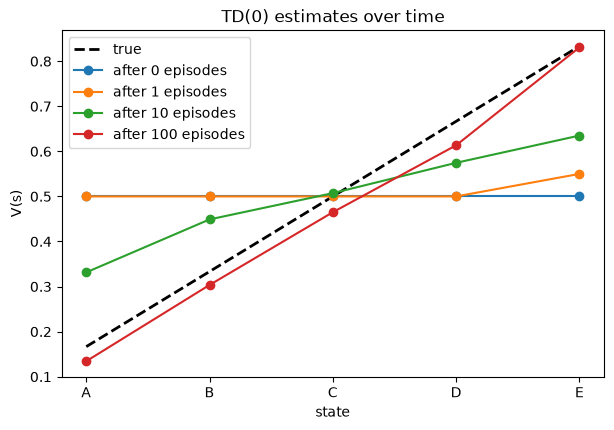

In [14]:
gen, V, done = torch.Generator().manual_seed(0), init_table(1), 0
plt.figure(figsize=(7, 4.5))
plt.plot(range(5), TRUE_V, "k--", lw=2, label="true")
for k in [0, 1, 10, 100]:
    while done < k:
        td0_update(V, *simulate(1, gen), 0.1)
        done += 1
    plt.plot(range(5), V[0, 1:6], "o-", label=f"after {k} episodes")
    print(f"after {k:>3} episodes: " + "  ".join(f"{NAMES[i]}={V[0, i+1]:.2f}" for i in range(5)))
plt.xticks(range(5), list(NAMES)); plt.xlabel("state"); plt.ylabel("V(s)")
plt.title("TD(0) estimates over time"); plt.legend(); plt.show()

## Experiment 2: Monte Carlo vs TD(0) learning curves

This recreates Sutton & Barto Figure 6.2, with each curve averaged over 100 runs.

MC     α=0.01  RMS after 100 episodes = 0.097
MC     α=0.02  RMS after 100 episodes = 0.079
MC     α=0.04  RMS after 100 episodes = 0.102
TD(0)  α=0.05  RMS after 100 episodes = 0.032
TD(0)  α=0.1   RMS after 100 episodes = 0.051
TD(0)  α=0.15  RMS after 100 episodes = 0.065


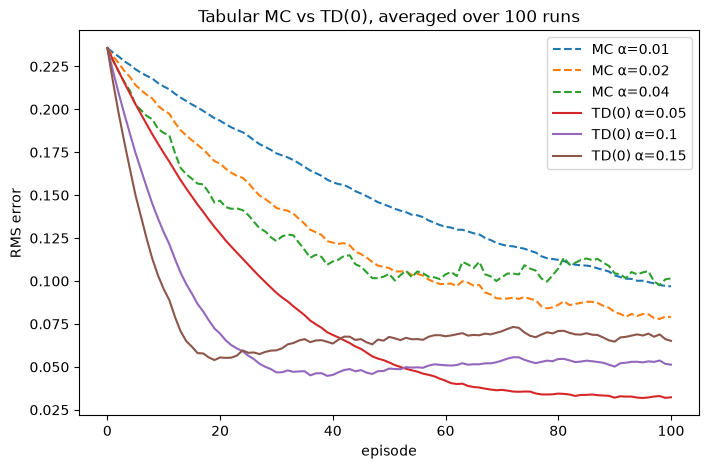

In [15]:
plt.figure(figsize=(8, 5))
for name, fn, alphas, style in [("MC", mc_update, [0.01, 0.02, 0.04], "--"),
                                ("TD(0)", td0_update, [0.05, 0.1, 0.15], "-")]:
    for alpha in alphas:
        c = learning_curve(fn, alpha)
        plt.plot(c, style, label=f"{name} α={alpha}")
        print(f"{name:<6} α={alpha:<5} RMS after 100 episodes = {c[-1]:.3f}")
plt.xlabel("episode"); plt.ylabel("RMS error")
plt.title("Tabular MC vs TD(0), averaged over 100 runs"); plt.legend(); plt.show()

**What to notice**
- TD(0) beats MC at every step size on this task. Monte Carlo targets carry the noise of the whole random
  episode, while TD targets depend on only one random step.
- Large α learns fast and then plateaus at a higher error. With a constant step size the estimates never
  stop chasing noise, so smaller α ends lower but needs more episodes.

## Experiment 3: n-step TD, the spectrum between TD(0) and MC

Each point is the mean RMS error over the first 10 episodes, averaged over 100 runs.

n=1 (TD(0))  best α=0.3  RMS=0.111
n=2          best α=0.2  RMS=0.126
n=4          best α=0.2  RMS=0.151
n=8          best α=0.1  RMS=0.174
n=∞ (MC)     best α=0.05 RMS=0.202


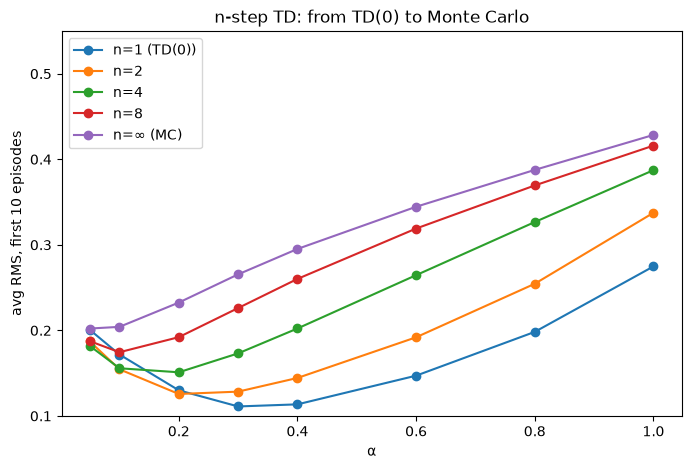

In [16]:
alphas = [0.05, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0]
plt.figure(figsize=(8, 5))
for n in [1, 2, 4, 8, INF]:
    errs = [learning_curve(nstep_update, a, episodes=10, runs=100, n=n)[1:].mean().item()
            for a in alphas]
    label = {1: "n=1 (TD(0))", INF: "n=∞ (MC)"}.get(n, f"n={n}")
    plt.plot(alphas, errs, "o-", label=label)
    best = min(range(len(alphas)), key=errs.__getitem__)
    print(f"{label:<12} best α={alphas[best]:<4} RMS={errs[best]:.3f}")
plt.ylim(0.1, 0.55); plt.xlabel("α"); plt.ylabel("avg RMS, first 10 episodes")
plt.title("n-step TD: from TD(0) to Monte Carlo"); plt.legend(); plt.show()

On this small, short-horizon task, more bootstrapping (small n) wins. On other problems an intermediate n
is often best. That observation is the motivation for TD(λ), which blends all values of n.

## Experiment 4: a neural-network value function

Replace the table with a small network $V_\theta(s)$ trained by gradient descent on $(\text{target} - V_\theta(s))^2$.

- **MC** becomes ordinary supervised regression onto the observed returns.
- **TD** needs one important detail: the target $r + \gamma V_\theta(s')$ depends on $\theta$ too, but we
  **don't backpropagate through it** (`torch.no_grad()`). This is the *semi-gradient* update. Letting gradients
  flow into the target changes the objective and typically learns worse or diverges.

MC: RMS after 10 ep = 0.280, after 100 ep = 0.125
TD: RMS after 10 ep = 0.393, after 100 ep = 0.125


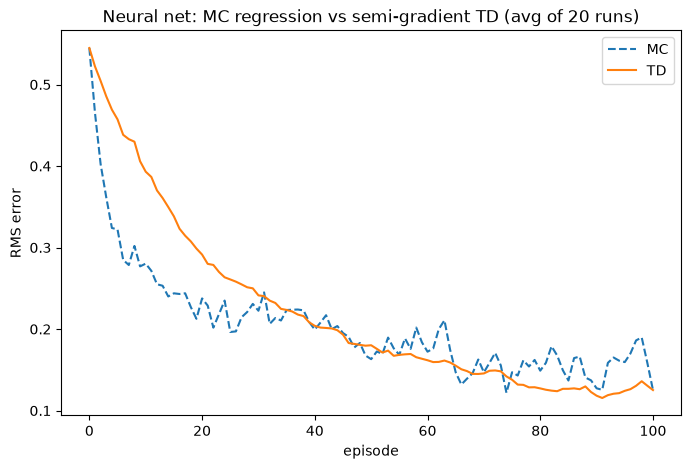

In [17]:
class ValueNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(N, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, s):
        v = self.net(nn.functional.one_hot(s, N).float()).squeeze(-1)
        terminal = (s == 0) | (s == N - 1)
        return torch.where(terminal, torch.zeros_like(v), v)     # V(terminal) = 0


def nn_curve(method, episodes=100, runs=20, lr=0.05):
    curve, states = torch.zeros(episodes + 1), torch.arange(N)
    for run in range(runs):
        torch.manual_seed(run)
        gen = torch.Generator().manual_seed(run)
        model = ValueNet()
        opt = torch.optim.SGD(model.parameters(), lr=lr)
        with torch.no_grad():
            curve[0] += rms(model(states)[None])
        for ep in range(episodes):
            S, R, valid = simulate(1, gen)
            T = int(valid.sum())
            s, s_next, r = S[:T, 0], S[1:T + 1, 0], R[1:T + 1, 0]
            if method == "MC":
                # reversed cumulative sum = return G_t (valid because gamma = 1)
                target = torch.flip(torch.cumsum(torch.flip(r, [0]), 0), [0])
            else:
                with torch.no_grad():                            # semi-gradient!
                    target = r + GAMMA * model(s_next)
            loss = ((target - model(s)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                curve[ep + 1] += rms(model(states)[None])
    return curve / runs


plt.figure(figsize=(8, 5))
for method, style in [("MC", "--"), ("TD", "-")]:
    c = nn_curve(method)
    plt.plot(c, style, label=method)
    print(f"{method}: RMS after 10 ep = {c[10]:.3f}, after 100 ep = {c[-1]:.3f}")
plt.xlabel("episode"); plt.ylabel("RMS error")
plt.title("Neural net: MC regression vs semi-gradient TD (avg of 20 runs)")
plt.legend(); plt.show()

**What to notice:** with a network, MC is faster at first, because its targets are correct from the start,
while TD's targets come from a network that is still badly wrong. Both reach a similar error by episode
100, and TD's curve is visibly smoother. This is the bias-variance trade-off in action.

## Summary

| | Monte Carlo | TD |
|---|---|---|
| Target | real return $G_t$ | $r + \gamma V(s')$ |
| Bias | unbiased | biased (bootstraps from estimates) |
| Variance | high (whole episode) | low (one step) |
| Needs episode end? | yes | no, works online and on continuing tasks |
| Typical behavior | slower, noisier | usually faster in practice |

**Things to try:** set `GAMMA = 0.9`, use a longer chain (larger `N`), sweep α for the network versions,
or remove `torch.no_grad()` in the TD network update to see why semi-gradient matters.